In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
EQ = '..//data//22_열처리.csv'

df = pd.read_csv(EQ)
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.set_index('timestamp').sort_index()
norm = df[['제어출력', '소입로온도']].asfreq('10s')

In [3]:
# ── [개념] ffill·bfill·선형/시간 보간·limit (설비센서) ──────────────────────

In [4]:
print('정규화 후 결측:', norm.isna().sum().to_dict())          # 22, 22

정규화 후 결측: {'제어출력': 22, '소입로온도': 22}


In [5]:
s = pd.Series([10.0, np.nan, 40.0], index=pd.to_datetime(
    ['2024-03-01 09:00:00', '2024-03-01 09:00:10', '2024-03-01 09:01:00']))

In [6]:
s

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10     NaN
2024-03-01 09:01:00    40.0
dtype: float64

In [7]:
help(s.interpolate)

Help on method interpolate in module pandas.core.generic:

interpolate(
    method: InterpolateOptions = 'linear',
    *,
    axis: Axis = 0,
    limit: int | None = None,
    inplace: bool = False,
    limit_direction: Literal['forward', 'backward', 'both'] | None = None,
    limit_area: Literal['inside', 'outside'] | None = None,
    **kwargs
) -> Self method of pandas.Series instance
    Fill NaN values using an interpolation method.

    Please note that only ``method='linear'`` is supported for
    DataFrame/Series with a MultiIndex.

    Parameters
    ----------
    method : str, default 'linear'
        Interpolation technique to use. One of:

        * 'linear': Ignore the index and treat the values as equally
          spaced. This is the only method supported on MultiIndexes.
        * 'time': Works on daily and higher resolution data to interpolate
          given length of interval. This interpolates values based on
          time interval between observations.
        * '

In [8]:
s.interpolate(method='linear')

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10    25.0
2024-03-01 09:01:00    40.0
dtype: float64

In [ ]:
s.interpolate(method='time')

2024-03-01 09:00:00    10.0
2024-03-01 09:00:10    15.0
2024-03-01 09:01:00    40.0
dtype: float64

In [11]:
# 실습1 2시 10분까지 norm['제어출력']

In [12]:
norm['제어출력'].ffill()

timestamp
2024-03-01 09:00:00    0.426
2024-03-01 09:00:10    0.463
2024-03-01 09:00:20    0.438
2024-03-01 09:00:30    0.445
2024-03-01 09:00:40    0.421
                       ...  
2024-03-01 09:32:30    0.800
2024-03-01 09:32:40    0.800
2024-03-01 09:32:50    0.800
2024-03-01 09:33:00    0.800
2024-03-01 09:33:10    0.800
Freq: 10s, Name: 제어출력, Length: 200, dtype: float64

In [14]:
norm['제어출력'].ffill().isna().sum()

np.int64(0)

In [15]:
norm['제어출력'].bfill().isna().sum()

np.int64(0)

In [16]:
norm['제어출력'].ffill().bfill().isna().sum()

np.int64(0)

In [17]:
# 실습2 2시 17분

In [19]:
norm.index

DatetimeIndex(['2024-03-01 09:00:00', '2024-03-01 09:00:10',
               '2024-03-01 09:00:20', '2024-03-01 09:00:30',
               '2024-03-01 09:00:40', '2024-03-01 09:00:50',
               '2024-03-01 09:01:00', '2024-03-01 09:01:10',
               '2024-03-01 09:01:20', '2024-03-01 09:01:30',
               ...
               '2024-03-01 09:31:40', '2024-03-01 09:31:50',
               '2024-03-01 09:32:00', '2024-03-01 09:32:10',
               '2024-03-01 09:32:20', '2024-03-01 09:32:30',
               '2024-03-01 09:32:40', '2024-03-01 09:32:50',
               '2024-03-01 09:33:00', '2024-03-01 09:33:10'],
              dtype='datetime64[us]', name='timestamp', length=200, freq='10s')

In [21]:
norm.index.to_series()

timestamp
2024-03-01 09:00:00   2024-03-01 09:00:00
2024-03-01 09:00:10   2024-03-01 09:00:10
2024-03-01 09:00:20   2024-03-01 09:00:20
2024-03-01 09:00:30   2024-03-01 09:00:30
2024-03-01 09:00:40   2024-03-01 09:00:40
                              ...        
2024-03-01 09:32:30   2024-03-01 09:32:30
2024-03-01 09:32:40   2024-03-01 09:32:40
2024-03-01 09:32:50   2024-03-01 09:32:50
2024-03-01 09:33:00   2024-03-01 09:33:00
2024-03-01 09:33:10   2024-03-01 09:33:10
Freq: 10s, Name: timestamp, Length: 200, dtype: datetime64[us]

In [22]:
norm.index.to_series().value_counts()

timestamp
2024-03-01 09:00:00    1
2024-03-01 09:00:10    1
2024-03-01 09:00:20    1
2024-03-01 09:00:30    1
2024-03-01 09:00:40    1
                      ..
2024-03-01 09:32:30    1
2024-03-01 09:32:40    1
2024-03-01 09:32:50    1
2024-03-01 09:33:00    1
2024-03-01 09:33:10    1
Name: count, Length: 200, dtype: int64

In [23]:
all(norm.index.to_series().value_counts() == 1)

True

In [24]:
# ── [실습 2] 보간 방법 비교 (선형·시간) ─────────────────────────────────────
lin = norm['제어출력'].interpolate()
tim = norm['제어출력'].interpolate(method='time')

In [27]:
(lin != tim).sum()

np.int64(0)

In [28]:
# 0 (균일 격자라 동일)

In [29]:
# limit=2 옵션을 사용하면 연속된 결측 구간에서 최대 2개까지만 채워집니다.
# 연속으로 이어진 결측을 최대 2개까지만 채웁니다.
# 3개 이상 연속된 결측 구간은 앞쪽 2개만 채우고 나머지는 NaN으로 남깁니다.

In [31]:
# 실습3 10시 30분까지 , 13개 확인

In [32]:
isna = norm['제어출력'].isna()

In [33]:
groups = (isna != isna.shift()).cumsum()

In [34]:
groups

timestamp
2024-03-01 09:00:00     1
2024-03-01 09:00:10     1
2024-03-01 09:00:20     1
2024-03-01 09:00:30     1
2024-03-01 09:00:40     1
                       ..
2024-03-01 09:32:30    15
2024-03-01 09:32:40    15
2024-03-01 09:32:50    15
2024-03-01 09:33:00    15
2024-03-01 09:33:10    15
Freq: 10s, Name: 제어출력, Length: 200, dtype: int64

In [36]:
isna.groupby(groups).sum()

제어출력
1      0
2      1
3      0
4     10
5      0
6      1
7      0
8      7
9      0
10     1
11     0
12     1
13     0
14     1
15     0
Name: 제어출력, dtype: int64

In [37]:
runs = isna.groupby(groups).sum()

In [38]:
runs[runs > 0]

제어출력
2      1
4     10
6      1
8      7
10     1
12     1
14     1
Name: 제어출력, dtype: int64

In [40]:
sorted(runs[runs > 0])

[1, 1, 1, 1, 1, 7, 10]

In [42]:
# 실습4  2시 48분

In [43]:
print('복원 전:', norm.isna().sum().to_dict())        # 22, 22
restored = norm.interpolate(method='time')

복원 전: {'제어출력': 22, '소입로온도': 22}


In [44]:
print('복원 후:', restored.isna().sum().to_dict())     # 0, 0

복원 후: {'제어출력': 0, '소입로온도': 0}


In [45]:
was_na = norm['제어출력'].isna()

In [46]:
was_na

timestamp
2024-03-01 09:00:00    False
2024-03-01 09:00:10    False
2024-03-01 09:00:20    False
2024-03-01 09:00:30    False
2024-03-01 09:00:40    False
                       ...  
2024-03-01 09:32:30    False
2024-03-01 09:32:40    False
2024-03-01 09:32:50    False
2024-03-01 09:33:00    False
2024-03-01 09:33:10    False
Freq: 10s, Name: 제어출력, Length: 200, dtype: bool

In [47]:
restored['제어출력'][was_na]

timestamp
2024-03-01 09:02:30    0.405000
2024-03-01 09:05:00    0.389273
2024-03-01 09:05:10    0.389545
2024-03-01 09:05:20    0.389818
2024-03-01 09:05:30    0.390091
2024-03-01 09:05:40    0.390364
2024-03-01 09:05:50    0.390636
2024-03-01 09:06:00    0.390909
2024-03-01 09:06:10    0.391182
2024-03-01 09:06:20    0.391455
2024-03-01 09:06:30    0.391727
2024-03-01 09:07:50    0.385000
2024-03-01 09:10:00    0.407250
2024-03-01 09:10:10    0.410500
2024-03-01 09:10:20    0.413750
2024-03-01 09:10:30    0.417000
2024-03-01 09:10:40    0.420250
2024-03-01 09:10:50    0.423500
2024-03-01 09:11:00    0.426750
2024-03-01 09:14:40    0.532500
2024-03-01 09:22:00    0.770500
2024-03-01 09:28:20    0.800000
Name: 제어출력, dtype: float64

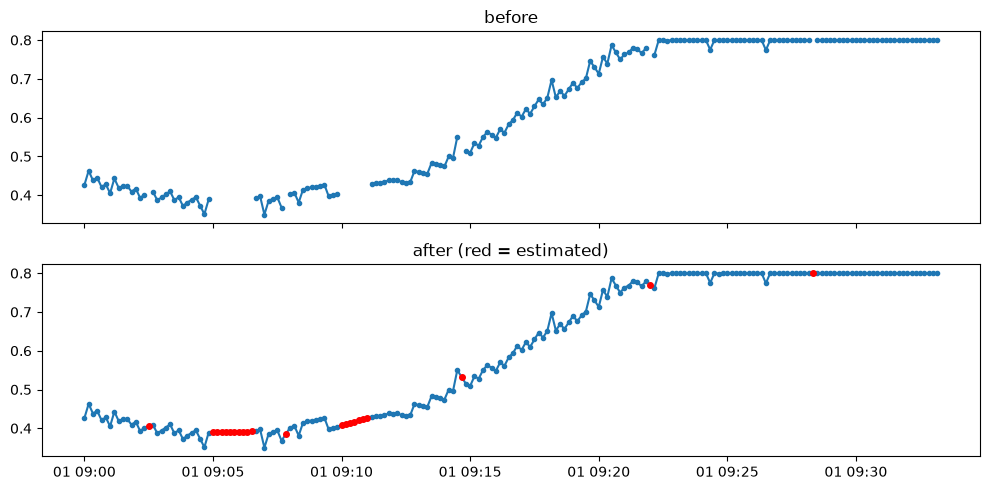

In [48]:
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(norm.index, norm['제어출력'], marker='.'); ax[0].set_title('before')
ax[1].plot(restored.index, restored['제어출력'], marker='.')
ax[1].plot(restored.index[was_na], restored['제어출력'][was_na], 'ro', markersize=4)
ax[1].set_title('after (red = estimated)'); plt.tight_layout()
plt.show()

In [49]:
# 교재대로 하신 후에 3시 40분까지 여러분의 데이터로 오늘 배운 내용 충실히 반영 하신 후에 
# 3시 40분에 3분 발표